# E1 · Capa Plata, limpieza y puerta de calidad — ObraPrecio (TRUSTED DATA LAB)

**Pregunta del producto:** ¿cuánto ha subido el costo de construir una vivienda en mi ciudad, y qué lo está moviendo: los materiales, la maquinaria o la mano de obra?

Este cuaderno es la **evidencia** del pipeline de limpieza. El código que corre en automático vive en `pipeline/` (lo ejecuta GitHub Actions); aquí se usan esas mismas funciones y se muestra con datos por qué se tomó cada decisión.

| Sección | Criterio de la rúbrica |
|---|---|
| 1 | Integración de fuentes heterogéneas y resolución de conflictos |
| 2 | Puerta de calidad automática (Pandera) y cuarentena |
| 3 | Valores faltantes: mecanismo (MCAR/MAR/MNAR) e imputación justificada |
| 4 | Atípicos y ruido: IQR, Z robusto, Isolation Forest |
| 5 | Normalización Min-Max y Z-Score |
| 6 | Discretización y jerarquías conceptuales |
| 7 | Reducción de datos: agregación, selección de variables y muestreo |

**Para reproducirlo:** `pip install -r requirements-dev.txt`, `python -m pipeline.ejecutar` y después ejecutar este cuaderno desde la raíz del repositorio.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

RAIZ = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parents[1]
sys.path.insert(0, str(RAIZ))
from extractores import inegi
from pipeline import catalogos, limpieza, oro, plata, puerta

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# Estilo de las graficas: un color fijo por componente (siempre el mismo), ejes discretos
COLOR = {"general": "#2a78d6", "materiales": "#eb6834", "maquinaria": "#1baf7a", "mano_obra": "#eda100"}
NOMBRE = {"general": "General", "materiales": "Materiales", "maquinaria": "Alquiler de maquinaria", "mano_obra": "Mano de obra"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781", "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 9.5, "lines.linewidth": 2, "figure.dpi": 110})

inpp = pd.read_csv(RAIZ / "data/plata/inpp_construccion.csv", parse_dates=["fecha"], dtype={"serie": str})
fix = pd.read_csv(RAIZ / "data/plata/fix_diario.csv", parse_dates=["fecha"])
panel = pd.read_csv(RAIZ / "data/oro/obraprecio_panel_mensual.csv", parse_dates=["fecha"], dtype={"serie": str})
q_inpp = pd.read_csv(RAIZ / "data/cuarentena/inegi_inpp.csv", dtype=str)
reporte = json.loads((RAIZ / "calidad/reporte-puerta.json").read_text(encoding="utf-8"))
series = inegi.cargar_series()
print(f"Plata INPP: {len(inpp):,} filas | {inpp.serie.nunique()} series | {inpp.ciudad_id.nunique()} ciudades (incluye Nacional) | {inpp.fecha.min():%Y-%m} a {inpp.fecha.max():%Y-%m}")
print(f"Plata FIX : {len(fix):,} dias  | {fix.fecha.min():%Y-%m-%d} a {fix.fecha.max():%Y-%m-%d}")
print(f"Oro panel : {len(panel):,} filas | desde {panel.fecha.min():%Y-%m}")

Plata INPP: 71,788 filas | 188 series | 47 ciudades (incluye Nacional) | 1973-01 a 2026-10
Plata FIX : 3,602 dias  | 2017-01-02 a 2026-11-12
Oro panel : 51,512 filas | desde 2004-01


## 1. Integración de fuentes heterogéneas y resolución de conflictos

ObraPrecio integra dos fuentes públicas que **no se parecen en nada**. Así llegan a la capa bronce (bytes exactos, sin tocar):

In [2]:
import gzip
b_inegi = sorted((RAIZ / "data/bronce/inegi_inpp/historico").glob("*.csv.gz"))[0]
texto = gzip.open(b_inegi).read().decode("cp1252").splitlines()
i = next(k for k, l in enumerate(texto) if l.startswith('"Fecha"'))
print("INEGI ·", b_inegi.name, "(CSV ancho, Windows-1252)")
for l in texto[:4] + [texto[i][:60] + " ...", texto[i + 1][:60] + " ..."]: print("   ", l[:110])
b_bmx = sorted((RAIZ / "data/bronce/banxico_sie/historico").glob("*.json.gz"))[-1]
print("\nBanxico ·", b_bmx.name, "(JSON anidado, UTF-8)")
print("   ", gzip.open(b_bmx).read().decode()[:60], "...", json.loads(gzip.open(b_bmx).read())["bmx"]["series"][0]["datos"][:2])

INEGI · 1973_2026_e9000_g00.csv.gz (CSV ancho, Windows-1252)
    "Instituto Nacional de Estadística y Geografía",
    "",
    "Construcción residencial por ciudad",
    "Fecha de consulta: 13/11/2026 16:26:17",
    "Fecha","1660002","1660003","1660004","1660005","1660006","1 ...
    "Ene 1973","0.015463114498","0.011501262689","N/E","0.038594 ...

Banxico · 2026-01-01_2026-11-08.json.gz (JSON anidado, UTF-8)
    {"bmx":{"series":[{"idSerie":"SF43718","titulo":"Tipo de cam ... [{'fecha': '02/01/2026', 'dato': '17.8803'}, {'fecha': '05/01/2026', 'dato': '17.8905'}]


| Discrepancia | INEGI · INPP construcción residencial | Banxico · FIX | Cómo se resuelve en `pipeline/plata.py` |
|---|---|---|---|
| Formato y esquema | CSV **ancho**: una columna por serie, 13 filas de metadatos arriba | JSON anidado `bmx.series[].datos[]` | Ambas pasan a tabla **larga** con columnas tipadas |
| Codificación | Windows-1252 | UTF-8 | Se decodifica con la codificación guardada en el `.meta.json`; plata siempre es UTF-8 |
| Fecha | Texto en español `"Ene 2023"` (mensual) | Texto `"02/01/2026"` día/mes/año (diaria) | Ambas a `datetime`; INEGI al día 1 del mes |
| Granularidad | Mensual | Diaria (solo días hábiles bancarios) | El FIX se agrega a mes (promedio y cierre) para unirse por `fecha` |
| Valor | Texto con 12 decimales | Texto con 4 decimales | `float`; lo no numérico va a cuarentena |
| Marca de "sin dato" | `N/E` | `N/E` | Nunca se convierte a 0 ni se borra: va a cuarentena con motivo |
| Llave | Clave de serie (`672880`) que hay que cruzar con un catálogo | `idSerie` | Catálogo versionado `extractores/inegi_series.json` |
| Nombres | `"Villahermosa,Tab."`, `"Cd. Jiménez Chih."`, `"-- Materiales de construcción"` | — | Catálogo explícito `pipeline/catalogos.py`; lo que no esté en catálogo va a cuarentena, no se adivina |
| Traslape entre capturas | La captura semanal repite meses ya bajados | La captura diaria repite los últimos 10 días | Mismo valor: se colapsa. Valor distinto (la fuente revisó la cifra): gana la captura más reciente y la anterior va a cuarentena |

In [3]:
crudo_fix = plata.leer_banxico()
print(f"Banxico en bronce: {len(crudo_fix):,} registros en {crudo_fix.archivo_bronce.nunique()} archivos "
      f"-> {crudo_fix.periodo.nunique():,} fechas distintas.")
rep = crudo_fix.groupby("periodo").agg(copias=("valor", "size"), valores_distintos=("valor", "nunique"))
print(f"Fechas repetidas entre capturas: {(rep.copias > 1).sum()} | con valor distinto (revisiones de la fuente): {(rep.valores_distintos > 1).sum()}")
print("\nNombres de la fuente que se normalizaron:")
display(pd.DataFrame([{"en la fuente": s["ciudad_fuente"], **catalogos.ciudad(s["ciudad_fuente"])}
    for s in series if s["ciudad_fuente"] in ("Villahermosa,Tab.", "Cd. Jiménez Chih.", "Área Metropolitana de la Cd. de México", "Colima, Col.") and s["componente"] == "general"]))
raros = sorted({s["nombre_fuente"] for s in series if s["nombre_fuente"].startswith("-")})
print("Componentes con guiones en la fuente:", raros, "-> 'materiales' en", sum(s["nombre_fuente"].startswith("-") for s in series), "series")

Banxico en bronce: 2,509 registros en 15 archivos -> 2,481 fechas distintas.
Fechas repetidas entre capturas: 8 | con valor distinto (revisiones de la fuente): 0

Nombres de la fuente que se normalizaron:


,en la fuente,ciudad,ciudad_id,estado,region
0,Área Metropolitana de la Cd. de México,Ciudad de México (AM),ciudad_de_mexico_am,Ciudad de México,Centro
1,"Villahermosa,Tab.",Villahermosa,villahermosa,Tabasco,Sur
2,"Colima, Col.",Colima,colima,Colima,Centro Norte
3,Cd. Jiménez Chih.,Ciudad Jiménez,ciudad_jimenez,Chihuahua,Norte


Componentes con guiones en la fuente: ['-- Materiales de construcción'] -> 'materiales' en 1 series


### Cambio de estructura en la fuente (resuelto durante E1)

INEGI actualizó la canasta del índice en agosto de 2025 y lo publica desde entonces en una **estructura nueva, con otras claves de serie**. La estructura anterior quedó congelada en julio de 2025. La primera captura de E1 se hizo sobre la anterior; al detectar que los datos terminaban en julio de 2025 se localizó la vigente y se volvió a capturar. Las dos capturas siguen en bronce. El pipeline solo lee la vigente y el reporte dice cuántos archivos de la anterior dejó sin leer. Antes de confiar en el cambio se compararon las dos en todo el periodo que comparten:

In [4]:
from extractores import config
ant = json.loads((RAIZ / "extractores/inegi_series_estructura_anterior.json").read_text(encoding="utf-8"))["series"]
viejo, _ = plata.limpiar_inegi(plata.leer_inegi(estructura=config.INEGI_ESTRUCTURA_ANTERIOR), ant)
cmp_e = viejo.merge(inpp, on=["ciudad_id", "componente", "fecha"], suffixes=("_anterior", "_vigente"))
dif = (cmp_e.indice_vigente - cmp_e.indice_anterior).abs()
print(f"Estructura anterior: {len(viejo):,} valores, hasta {viejo.fecha.max():%Y-%m} | vigente: {len(inpp):,} valores, hasta {inpp.fecha.max():%Y-%m}")
print(f"Valores comparados (misma ciudad, componente y mes): {len(cmp_e):,} | diferencia máxima: {dif.max():.1e} | valores distintos (> 1e-9): {(dif > 1e-9).sum()}")
print(f"Meses nuevos que aporta la vigente: {inpp.loc[inpp.fecha > viejo.fecha.max(), 'fecha'].nunique()} | claves de serie en común: {len(set(viejo.serie) & set(inpp.serie))}")
print("Archivos de bronce no leídos por ser de la estructura anterior:", reporte["estructura_inegi"]["archivos_de_estructuras_anteriores_no_leidos"])

Estructura anterior: 68,968 valores, hasta 2025-07 | vigente: 71,788 valores, hasta 2026-10
Valores comparados (misma ciudad, componente y mes): 68,968 | diferencia máxima: 1.0e-12 | valores distintos (> 1e-9): 0
Meses nuevos que aporta la vigente: 15 | claves de serie en común: 0
Archivos de bronce no leídos por ser de la estructura anterior: {'1120015000400010': 4}


Las dos estructuras coinciden en todos los valores del periodo común; la vigente solo agrega los meses nuevos. El cambio de claves se resuelve integrando por ciudad y componente, no por clave de serie.

**Resultado de la integración.** Las dos fuentes quedan unidas por mes en la capa oro. El tipo de cambio solo existe en bronce desde 2017 (así se definió la captura en E0), por eso la columna `fix_promedio` está vacía antes de esa fecha; no se rellena con nada.

In [5]:
col = panel[(panel.ciudad_id == "colima") & (panel.componente == "general")]
display(col[["fecha", "ciudad", "region", "indice", "var_anual_pct", "var_anual_nacional_pct", "nivel_inflacion", "fix_promedio"]].tail(4))
print(f"Meses con FIX en oro: {panel.loc[panel.fix_promedio.notna(), 'fecha'].min():%Y-%m} a {panel.loc[panel.fix_promedio.notna(), 'fecha'].max():%Y-%m}")

,fecha,ciudad,region,indice,var_anual_pct,var_anual_nacional_pct,nivel_inflacion,fix_promedio
10134,2026-07-01,Colima,Centro Norte,162.536,6.879,5.629,alta,17.461
10135,2026-08-01,Colima,Centro Norte,161.919,6.436,5.824,alta,17.066
10136,2026-09-01,Colima,Centro Norte,162.786,6.246,5.697,alta,17.264
10137,2026-10-01,Colima,Centro Norte,163.155,6.328,6.046,alta,18.434


Meses con FIX en oro: 2017-01 a 2026-10


## 2. Puerta de calidad automática y cuarentena

Entre bronce y plata hay una puerta (`pipeline/puerta.py`) con dos niveles:

1. **Contrato por registro (Pandera, validación completa `lazy=True`)**: tipos, formato de la clave, fecha en rango y en día 1, catálogo de componentes y regiones, índice positivo y menor a 1000, FIX entre 5 y 40 y nunca en fin de semana, llave única. Además, un salto mensual mayor a 60 % se trata como error de captura.
2. **Revisiones de conjunto**: continuidad mensual, cobertura de series, que julio 2019 valga exactamente 100 (la base del índice), que cada ciudad tenga sus 4 componentes y cobertura de días hábiles del FIX. Una revisión grave detiene el pipeline con código de salida 1.

Todo registro rechazado se escribe en `data/cuarentena/` con `etapa` y `motivo`. **Ninguno se borra en silencio**; la prueba `test_ningun_registro_se_pierde_en_silencio` lo verifica.

In [6]:
filas = []
for fuente in ("inegi_inpp", "banxico_sie"):
    r = reporte[fuente]
    filas.append({"fuente": fuente, "bronce": r["registros_bronce"], "plata": r["registros_plata"], "cuarentena": r["registros_cuarentena"],
                  "duplicados idénticos colapsados": r["duplicados_identicos_colapsados"], "% aceptado": r["pct_aceptado"]})
t = pd.DataFrame(filas); display(t)
assert (t.bronce == t.plata + t.cuarentena + t["duplicados idénticos colapsados"]).all(), "se perdio un registro"
print("Balance verificado: bronce = plata + cuarentena + duplicados idénticos, en las dos fuentes.\n")
print("Cuarentena por motivo:")
display(pd.DataFrame(reporte["inegi_inpp"]["cuarentena_por_motivo"] + reporte["banxico_sie"]["cuarentena_por_motivo"]))
display(pd.DataFrame(reporte["revisiones_de_conjunto"])[["revision", "ok", "detalle"]])

,fuente,bronce,plata,cuarentena,duplicados idénticos colapsados,% aceptado
0,inegi_inpp,96392,71788,24604,0,74.480
1,banxico_sie,2509,2481,0,28,98.880


Balance verificado: bronce = plata + cuarentena + duplicados idénticos, en las dos fuentes.

Cuarentena por motivo:


,etapa,motivo,n
0,formato,valor_no_existe_en_fuente_NE,24604


,revision,ok,detalle
0,continuidad_mensual,True,0 meses faltantes dentro de las series
1,cobertura_de_series,True,188 de 188 series con datos; faltan: []
2,base_julio_2019_igual_a_100,True,188 series en julio 2019; desviacion maxima re...
3,ciudades_con_los_4_componentes,True,47 ciudades; incompletas: []
4,fix_dias_habiles_cubiertos,True,93 de 2574 dias de lunes a viernes sin FIX (3....
5,tablas_no_vacias,True,"inpp=71788 filas, fix=2481 filas"


En la corrida real los únicos rechazos son las celdas `N/E` de INEGI (se analizan en la sección 3). Los datos oficiales no traen índices negativos ni fechas imposibles, así que para **demostrar que la puerta sí detiene basura** se le inyectan a propósito cinco registros defectuosos a una copia en memoria. Esto es una prueba, no datos del proyecto.

In [7]:
muestra = inpp[inpp.ciudad_id == "colima"].head(8).copy()
muestra.loc[muestra.index[0], "indice"] = -12.5                      # indice negativo
muestra.loc[muestra.index[1], "indice"] = 15000.0                    # fuera de rango
muestra.loc[muestra.index[2], "componente"] = "acabados"             # fuera de catalogo
muestra.loc[muestra.index[3], "fecha"] = pd.Timestamp("2031-01-01")  # fecha futura
muestra.loc[muestra.index[4], "serie"] = "67-A"                      # clave mal formada
validos, rechazados = puerta.validar(muestra, puerta.ESQUEMA_INPP)
print(f"Entraron {len(muestra)} | pasan {len(validos)} | a cuarentena {len(rechazados)}")
display(rechazados[["serie", "fecha", "componente", "indice", "motivo"]])

Entraron 8 | pasan 3 | a cuarentena 5


,serie,fecha,componente,indice,motivo
index,,,,,
0,1660106,2003-12-01,general,-12.500,indice: indice_no_positivo
1,1660106,2004-01-01,general,"15,000.000",indice: indice_fuera_de_rango (>1000)
2,1660106,2004-02-01,acabados,45.528,componente: componente_fuera_de_catalogo
3,1660106,2031-01-01,general,48.480,fecha: fecha_futura
4,67-A,2004-04-01,general,49.883,serie: serie_formato_invalido


## 3. Valores faltantes: diagnóstico del mecanismo e imputación

### 3.1 ¿Dónde faltan datos?

Se arma la rejilla completa serie × mes (188 series × todos los meses desde 1973) y se marca qué celdas no existen. De esas celdas, la fuente declaró 24,604 de forma explícita con `N/E` (son las que están en cuarentena); el resto son meses que la exportación ni siquiera incluye, porque en ese bloque de consulta todavía no existía ninguna serie.

Celdas: 121,448 | faltantes: 49,660 (40.9 %) | faltantes DENTRO de una serie ya iniciada: 0
Celdas N/E en cuarentena: 24,604


primer mes con dato,1973-01,1981-01,2003-12
componente,,,
general,1,23,23
mano_obra,1,23,23
maquinaria,0,0,47
materiales,1,23,23


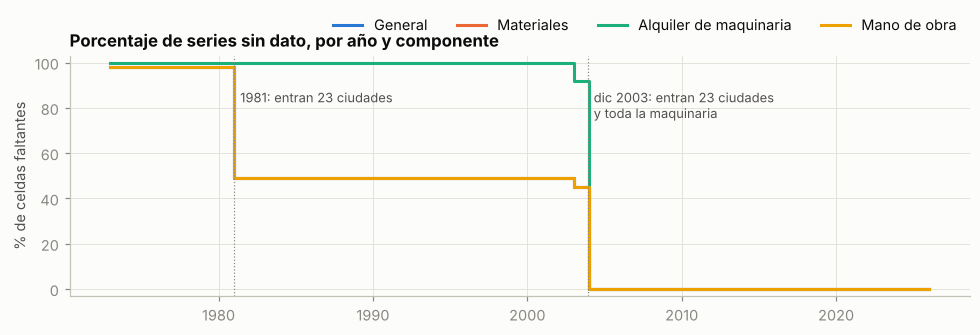

Nota: General, Materiales y Mano de obra tienen exactamente el mismo calendario; sus líneas quedan encimadas.


In [8]:
rej = limpieza.rejilla_completa(inpp)
diag = limpieza.diagnostico_faltantes(rej)
print(f"Celdas: {diag['celdas']:,} | faltantes: {diag['faltantes']:,} ({diag['pct_faltante']:.1f} %) | faltantes DENTRO de una serie ya iniciada: {diag['faltantes_interiores']}")
print(f"Celdas N/E en cuarentena: {(q_inpp.motivo == 'valor_no_existe_en_fuente_NE').sum():,}")
ini = diag["inicio_por_serie"].rename("inicio").reset_index().merge(inpp.drop_duplicates("serie")[["serie", "componente"]])
display(ini.groupby(["componente", ini.inicio.dt.strftime("%Y-%m")]).size().unstack(fill_value=0).rename_axis(columns="primer mes con dato"))

pct = rej.assign(anio=rej.fecha.dt.year).groupby(["componente", "anio"]).falta.mean().unstack(0) * 100
fig, ax = plt.subplots(figsize=(9, 3.2))
for c in catalogos.COMPONENTES:
    ax.step(pct.index, pct[c], where="post", color=COLOR[c], label=NOMBRE[c])
ax.set(title="Porcentaje de series sin dato, por año y componente", ylabel="% de celdas faltantes", ylim=(-3, 103))
for x, txt in ((1981, "1981: entran 23 ciudades"), (2003.9, "dic 2003: entran 23 ciudades\ny toda la maquinaria")):
    ax.axvline(x, color="#898781", lw=0.8, ls=":"); ax.text(x + 0.4, 88, txt, color="#52514e", fontsize=8.5, va="top")
ax.legend(frameon=False, ncol=4, loc="upper right", bbox_to_anchor=(1, 1.22)); plt.tight_layout(); plt.show()
print("Nota: General, Materiales y Mano de obra tienen exactamente el mismo calendario; sus líneas quedan encimadas.")

### 3.2 ¿MCAR, MAR o MNAR?

- **MCAR** (completamente al azar) exigiría que faltar no dependa de nada. Se contrasta con ji-cuadrada la independencia entre "falta" y tres variables que sí se observan.
- **MNAR** exigiría que falte *por el valor mismo* (por ejemplo, que no se publiquen los meses con índice alto).

In [9]:
display(pd.DataFrame(diag["pruebas"]).T.rename(columns={"chi2": "ji-cuadrada", "p": "valor p", "v_cramer": "V de Cramér"}))
print("Diagnóstico automático:", diag["mecanismo"])

,ji-cuadrada,valor p,V de Cramér
decada,"60,130.984",0.000,0.704
componente,"4,582.304",0.000,0.194
region,"1,078.665",0.000,0.094


Diagnóstico automático: MAR estructural (por diseno): la serie aun no existia en ese periodo


**Diagnóstico.** No es MCAR: faltar depende fuertemente de la década y del componente (valor p ≈ 0, V de Cramér alta). Tampoco hay evidencia de MNAR: los faltantes no están salpicados entre los datos, están **todos al inicio de cada serie** (0 huecos interiores) y la fuente los declara con `N/E` y con el "periodo disponible" de cada serie. Es un faltante **MAR de tipo estructural (por diseño)**: la serie Nacional existe desde 1973, 23 ciudades se incorporan en 1981 y otras 23 en diciembre de 2003; el componente de maquinaria se mide en todas desde diciembre de 2003. Colima entra en esa última oleada.

**Decisión: no se imputa hacia atrás.** Rellenar 1973–2003 para Colima sería inventar 30 años de historia de una ciudad que nadie midió. En su lugar:

- Plata conserva cada serie desde su primer dato real.
- Oro arranca en **enero de 2004**, donde las 188 series están completas (panel balanceado, 0 % de faltantes en el índice).
- Las celdas `N/E` quedan en cuarentena con su motivo, por si se quiere auditar.

### 3.3 ¿Y si mañana aparece un hueco? Método elegido con evidencia

Hoy no hay huecos interiores, pero la captura es automática y puede fallar un mes. Para no escoger el método "a ojo" se hace un experimento: se ocultan al azar 5 % de valores **conocidos** del índice general (2004 en adelante) y se mide qué método los recupera mejor.

,metodo,n_ocultos,MAE,MAPE_pct
0,interpolacion_log (geometrica),656,0.336,0.392
1,interpolacion_lineal,656,0.336,0.392
2,razon_con_promedio_de_series,656,0.336,0.392
3,ultimo_valor (LOCF),656,0.643,0.763
4,media_de_la_serie,656,27.446,35.352


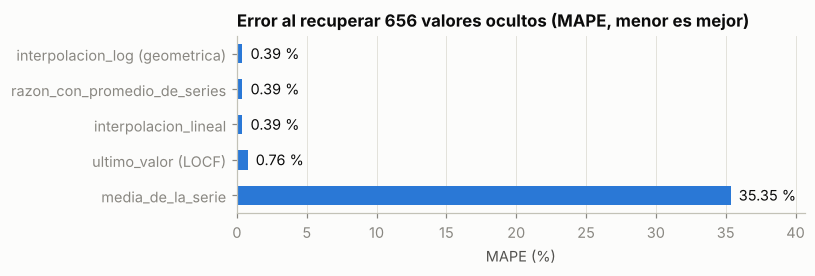

In [10]:
ancho = inpp[(inpp.componente == "general") & (inpp.fecha >= oro.ANALISIS_DESDE)].pivot(index="fecha", columns="ciudad_id", values="indice")
res = limpieza.evaluar_imputacion(ancho, fraccion=0.05)
display(res)
fig, ax = plt.subplots(figsize=(7.5, 2.6))
r = res.sort_values("MAPE_pct", ascending=False)
ax.barh(r.metodo, r.MAPE_pct, color="#2a78d6", height=0.55)
for y, v in enumerate(r.MAPE_pct): ax.text(v, y, f"  {v:.2f} %", va="center", color="#0b0b0b")
ax.set(title=f"Error al recuperar {res.n_ocultos[0]} valores ocultos (MAPE, menor es mejor)", xlabel="MAPE (%)"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, r.MAPE_pct.max() * 1.15); plt.tight_layout(); plt.show()

**Decisión.** Los tres mejores métodos quedan prácticamente empatados (MAPE cercano a 0.4 %). Para un hueco corto (1 a 2 meses) dentro de una serie se usará la **interpolación geométrica** (lineal en logaritmos): tiene el mismo error que la mejor y no depende de que las demás ciudades tengan dato ese mes. La fila llevará una bandera de imputado. El último valor (LOCF) duplica el error y la media de la serie es la peor opción con diferencia porque el índice tiene tendencia: imputar con la media metería un escalón falso. Para huecos largos no se imputa: la serie se reporta incompleta (la revisión `continuidad_mensual` de la puerta lo avisa).

### 3.4 Tipo de cambio: faltantes por calendario (MAR) e imputación LOCF

Banxico solo determina el FIX en días hábiles bancarios. El faltante de sábados, domingos y festivos depende del calendario (variable observada), así que es **MAR**. La regla para imputar no es estadística sino de negocio: el último FIX publicado sigue vigente hasta el siguiente. Por eso se usa **último valor observado (LOCF)** y se marca cada día imputado.

In [11]:
dia = fix.assign(dia=fix.fecha.dt.dayofweek)
t = dia.groupby("dia").imputado.agg(["mean", "sum"]); t.index = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
display((t.rename(columns={"mean": "% de días imputados", "sum": "días imputados"}).assign(**{"% de días imputados": lambda d: d["% de días imputados"] * 100})).T)
display(fix[fix.fecha.between("2026-10-30", "2026-11-04")])
print("El 2 de noviembre (festivo bancario) cae en lunes y queda imputado con el FIX del viernes anterior.")

,lun,mar,mié,jue,vie,sáb,dom
% de días imputados,7.767,1.553,1.942,3.495,3.307,100.000,100.000
días imputados,40.000,8.000,10.000,18.000,17.000,514.000,514.000


,fecha,fix,imputado
3588,2026-10-30,18.796,False
3589,2026-10-31,18.796,True
3590,2026-11-01,18.796,True
3591,2026-11-02,18.796,True
3592,2026-11-03,18.759,False
3593,2026-11-04,18.628,False


El 2 de noviembre (festivo bancario) cae en lunes y queda imputado con el FIX del viernes anterior.


## 4. Atípicos y ruido

La variable donde un error se nota es la **variación mensual** del índice (un dedazo en el nivel se ve como un salto). Antes de escoger método hay que ver la forma de los datos, porque los cuatro componentes no se comportan igual.

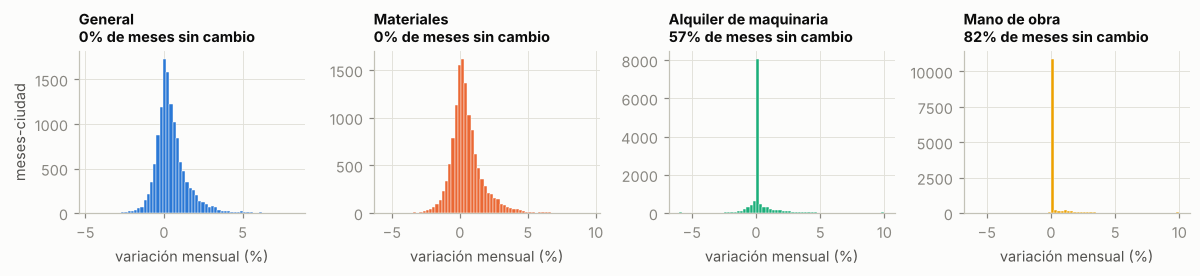

In [12]:
p = panel.dropna(subset=["var_mensual_pct"])
fig, axs = plt.subplots(1, 4, figsize=(11, 2.6), sharey=False)
for ax, c in zip(axs, catalogos.COMPONENTES):
    x = p.loc[p.componente == c, "var_mensual_pct"]
    ax.hist(x.clip(-6, 10), bins=64, color=COLOR[c], edgecolor="#fcfcfb", linewidth=0.3)
    ax.set_title(f"{NOMBRE[c]}\n{(x == 0).mean():.0%} de meses sin cambio", fontsize=9.5); ax.set_xlabel("variación mensual (%)")
axs[0].set_ylabel("meses-ciudad"); plt.tight_layout(); plt.show()

**Hallazgo (ruido de medición).** Mano de obra y alquiler de maquinaria son **series escalonadas**: la mayoría de los meses no cambian y de pronto dan un salto (revisión salarial, cambio de tarifa). Con más de la mitad de ceros, el IQR y el MAD valen 0 y *cualquier* ajuste saldría marcado como atípico. Por eso `limpieza.referencia()` mide lo "normal" de esas dos series solo contra los meses en que sí hubo cambio. La prueba `test_serie_escalonada_usa_solo_los_meses_con_cambio` cubre este caso.

Se aplican los tres métodos pedidos, dentro de cada componente:

| Método | Qué mira | Umbral |
|---|---|---|
| **IQR** (Tukey) | variación mensual | fuera de Q1 − 3·IQR, Q3 + 3·IQR (extremo, no moderado) |
| **Z robusto** (mediana y MAD) | variación mensual | \|z\| > 3.5 (Iglewicz y Hoaglin) |
| **Isolation Forest** | 3 variables: variación mensual, variación anual y brecha contra el nacional | 1 % de contaminación, semilla fija |

In [13]:
m = ["atipico_iqr", "atipico_z", "atipico_iforest"]
t = p.groupby("componente")[m].sum().reindex(catalogos.COMPONENTES)
t["2 o más métodos"] = p.groupby("componente").apply(lambda d: (d.atipico_votos >= 2).sum())
t["los 3"] = p.groupby("componente").apply(lambda d: (d.atipico_votos == 3).sum()); t["observaciones"] = p.groupby("componente").size()
display(t)
print("Concordancia entre métodos (coeficiente de Jaccard):")
jac = lambda a, b: (p[a] & p[b]).sum() / (p[a] | p[b]).sum()
display(pd.DataFrame([[jac(a, b) for b in m] for a in m], index=m, columns=m))

,atipico_iqr,atipico_z,atipico_iforest,2 o más métodos,los 3,observaciones
componente,,,,,,
general,155,455,127,173,53,12878
materiales,155,464,127,175,50,12878
maquinaria,219,489,124,229,51,12878
mano_obra,53,143,127,75,45,12878


Concordancia entre métodos (coeficiente de Jaccard):


,atipico_iqr,atipico_z,atipico_iforest
atipico_iqr,1.000,0.375,0.224
atipico_z,0.375,1.000,0.151
atipico_iforest,0.224,0.151,1.000


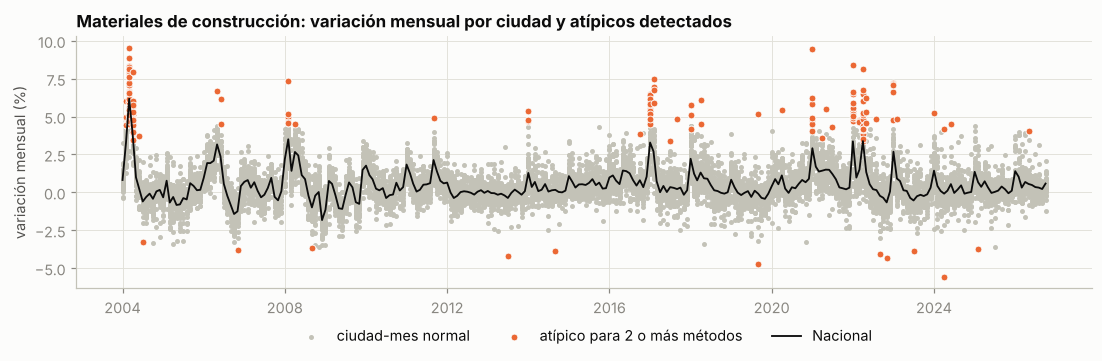

Meses con más ciudades atípicas en materiales: {'2004-03': 40, '2004-04': 15, '2017-01': 14, '2022-04': 14, '2022-01': 12, '2008-02': 8}


In [14]:
g = p[p.componente == "materiales"].sort_values("fecha")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.scatter(g.fecha, g.var_mensual_pct, s=5, color="#c3c2b7", label="ciudad-mes normal", rasterized=True)
f2 = g[g.atipico_votos >= 2]
ax.scatter(f2.fecha, f2.var_mensual_pct, s=20, color="#eb6834", edgecolor="#fcfcfb", linewidth=0.6, label="atípico para 2 o más métodos")
nac = g[g.ciudad_id == "nacional"]; ax.plot(nac.fecha, nac.var_mensual_pct, color="#0b0b0b", lw=1.2, label="Nacional")
ax.set(title="Materiales de construcción: variación mensual por ciudad y atípicos detectados", ylabel="variación mensual (%)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1)); plt.tight_layout(); plt.show()
top = f2.assign(mes=f2.fecha.dt.strftime("%Y-%m")).groupby("mes").size().sort_values(ascending=False).head(6)
print("Meses con más ciudades atípicas en materiales:", top.to_dict())

**Los atípicos no son errores, son la noticia.** No aparecen sueltos: se amontonan en los mismos meses en muchas ciudades a la vez: marzo y abril de 2004 (40 ciudades el mismo mes), enero de 2017 y el encarecimiento de materiales de 2021 y 2022, y en todos esos meses el índice Nacional también sube. Un error de captura afectaría a una ciudad aislada; un choque de precios afecta a todas. Además, ningún valor rompe la regla de salto implausible (> 60 %) de la puerta.

**Tratamiento: marcar, no borrar.**

- `indice` y `var_mensual_pct` se conservan tal cual. Un contratista quiere ver justo esos picos.
- Se agregan banderas `atipico_iqr`, `atipico_z`, `atipico_iforest` y `atipico_votos` (0 a 3) para que cada análisis decida.
- Se agrega `var_mensual_tratada_pct`, **winsorizada** a mediana ± 3.5 escalas robustas, para los modelos sensibles a extremos (regresión, PCA, pronóstico en la parte de Estadística). Recortar conserva la observación y su dirección; solo atenúa la magnitud.

In [15]:
cmp = p.groupby("componente")[["var_mensual_pct", "var_mensual_tratada_pct"]].agg(["min", "max", "std"]).reindex(catalogos.COMPONENTES)
cmp["% de valores recortados"] = (p.var_mensual_pct != p.var_mensual_tratada_pct).groupby(p.componente).mean() * 100
display(cmp)

var_mensual_pct              var_mensual_tratada_pct             % de valores recortados
                       min    max   std                     min   max   std                        
componente                                                                                         
general             -4.763  8.302 1.031                  -2.222 2.787 0.915                   3.533
materiales          -5.577  9.536 1.229                  -2.629 3.224 1.081                   3.603
maquinaria         -17.825 22.713 1.579                  -3.481 3.957 1.066                   3.797
mano_obra           -9.751 21.697 1.319                  -3.868 6.382 1.073                   1.110

## 5. Normalización y estandarización

El índice de las 188 series está en la misma unidad (base julio 2019 = 100), pero para **comparar la forma** de las trayectorias o para alimentar modelos basados en distancias hacen falta escalas comunes. Se guardan las dos transformaciones, cada una **dentro de su serie**:

- **Min-Max** del nivel (`indice_minmax`, 0 a 1): útil para el tablero (semáforos, mapas de calor) porque tiene mínimo y máximo fijos. Es sensible a extremos.
- **Z-Score** de la variación mensual (`var_mensual_z`, media 0 y desviación 1): útil para modelos (PCA, regresión, clustering) porque pone a competir en igualdad a mano de obra (muy volátil) con materiales.

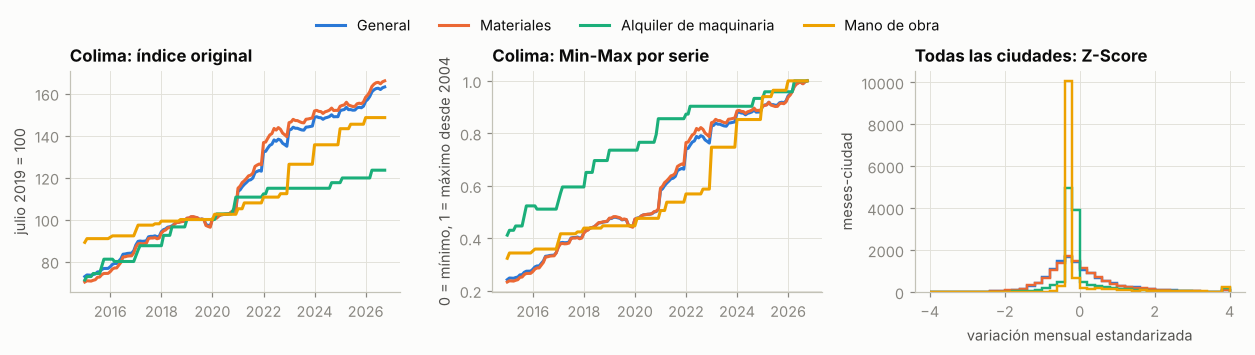

,minmax_min,minmax_max,z_media,z_desv
min,0.000,1.000,-0.000,1.000
max,0.000,1.000,0.000,1.000


In [16]:
sel = panel[(panel.ciudad_id.isin(["colima"])) & (panel.fecha >= "2015-01-01")]
fig, axs = plt.subplots(1, 3, figsize=(11.5, 3))
for c in catalogos.COMPONENTES:
    d = sel[sel.componente == c]
    axs[0].plot(d.fecha, d.indice, color=COLOR[c], label=NOMBRE[c]); axs[1].plot(d.fecha, d.indice_minmax, color=COLOR[c])
    axs[2].hist(panel.loc[panel.componente == c, "var_mensual_z"].clip(-4, 4), bins=40, histtype="step", color=COLOR[c], lw=1.6)
axs[0].set(title="Colima: índice original", ylabel="julio 2019 = 100"); axs[1].set(title="Colima: Min-Max por serie", ylabel="0 = mínimo, 1 = máximo desde 2004")
axs[2].set(title="Todas las ciudades: Z-Score", xlabel="variación mensual estandarizada", ylabel="meses-ciudad")
fig.legend(*axs[0].get_legend_handles_labels(), frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.08)); plt.tight_layout(); plt.show()
chk = panel.groupby("serie").agg(minmax_min=("indice_minmax", "min"), minmax_max=("indice_minmax", "max"), z_media=("var_mensual_z", "mean"), z_desv=("var_mensual_z", lambda v: v.std(ddof=0)))
display(chk.describe().loc[["min", "max"]])

La tabla confirma la transformación en las 188 series: Min-Max va exactamente de 0 a 1 y el Z-Score tiene media 0 y desviación 1 en cada serie.

## 6. Discretización y jerarquías conceptuales

**Discretización con cortes de negocio** (`nivel_inflacion`): la variación anual se convierte en una categoría ordenada. Los cortes no son arbitrarios: 3 % es la meta de inflación de Banco de México.

| Variación anual | < 0 % | 0 a 3 % | 3 a 6 % | 6 a 10 % | ≥ 10 % |
|---|---|---|---|---|---|
| `nivel_inflacion` | deflación | baja | moderada | alta | muy_alta |

**Discretización por igual frecuencia** (`costo_relativo`): cada mes, las ciudades se parten en terciles según su variación anual: `bajo`, `medio`, `alto`. Contesta "¿mi ciudad está entre las que más subieron este mes?" sin importar si el año fue caro o barato en general.

**Jerarquías conceptuales** (permiten subir y bajar de nivel en el tablero):

- Geográfica: `ciudad` → `estado` → `region` → Nacional. Regiones de los Reportes sobre las Economías Regionales de Banco de México.
- Temporal: `fecha` (mes) → `trimestre` → `anio`.
- Producto: `componente` (materiales, maquinaria, mano de obra) → `general`.

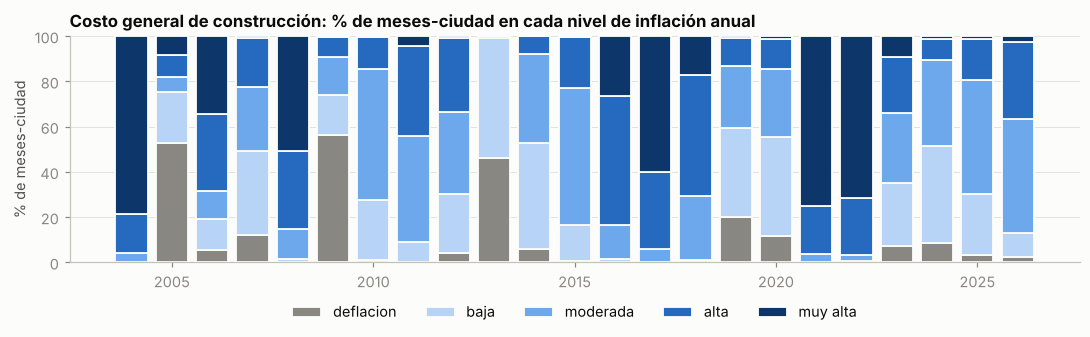

Jerarquía geográfica (ciudades por región y estado):


,estados,ciudades,ejemplo
region,,,
Centro,8,9,"Ciudad de México (AM), Cortazar, Cuernavaca, León"
Centro Norte,10,12,"Aguascalientes, Colima, Culiacán, Durango"
Norte,6,13,"Chihuahua, Ciudad Acuña, Ciudad Jiménez, Ciuda..."
Sur,8,12,"Acapulco, Campeche, Chetumal, Córdoba"


In [17]:
gen = panel[(panel.componente == "general") & (panel.ciudad_id != "nacional")].dropna(subset=["nivel_inflacion"])
dist = (gen.groupby(["anio", "nivel_inflacion"]).size().unstack(fill_value=0).reindex(columns=catalogos.NIVELES_INFLACION))
dist = dist.div(dist.sum(axis=1), axis=0) * 100
tonos = ["#898781", "#b7d3f6", "#6da7ec", "#256abf", "#0d366b"]  # gris = deflacion; azul claro a oscuro = mas inflacion
fig, ax = plt.subplots(figsize=(10, 3.2)); base = np.zeros(len(dist))
for n, col in zip(catalogos.NIVELES_INFLACION, tonos):
    ax.bar(dist.index, dist[n], bottom=base, color=col, width=0.8, edgecolor="#fcfcfb", linewidth=1.2, label=n.replace("_", " ")); base += dist[n].to_numpy()
ax.set(title="Costo general de construcción: % de meses-ciudad en cada nivel de inflación anual", ylabel="% de meses-ciudad", ylim=(0, 100)); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12)); plt.tight_layout(); plt.show()
print("Jerarquía geográfica (ciudades por región y estado):")
geo = inpp[inpp.ciudad_id != "nacional"].drop_duplicates("ciudad_id")
display(geo.groupby("region").agg(estados=("estado", "nunique"), ciudades=("ciudad", "nunique"), ejemplo=("ciudad", lambda c: ", ".join(sorted(c)[:4]))))

## 7. Reducción de datos

Tres técnicas, cada una con un uso concreto.

### 7.1 Agregación (subir por las jerarquías)

In [18]:
cm = pd.read_csv(RAIZ / "data/oro/obraprecio_ciudad_mensual.csv"); ra = pd.read_csv(RAIZ / "data/oro/resumen_region_anual.csv"); rk = pd.read_csv(RAIZ / "data/oro/ranking_ciudades.csv")
t = pd.DataFrame([
    {"tabla": "plata/inpp_construccion", "grano": "serie x mes (1973 en adelante)", "filas": len(inpp)},
    {"tabla": "oro/obraprecio_panel_mensual", "grano": "serie x mes (2004 en adelante)", "filas": len(panel)},
    {"tabla": "oro/obraprecio_ciudad_mensual", "grano": "ciudad x mes (4 componentes en columnas)", "filas": len(cm)},
    {"tabla": "oro/resumen_region_anual", "grano": "región x año x componente", "filas": len(ra)},
    {"tabla": "oro/ranking_ciudades", "grano": "ciudad (último mes)", "filas": len(rk)}])
t["reducción vs plata"] = (1 - t.filas / len(inpp)).map("{:.1%}".format); display(t)

,tabla,grano,filas,reducción vs plata
0,plata/inpp_construccion,serie x mes (1973 en adelante),71788,0.0%
1,oro/obraprecio_panel_mensual,serie x mes (2004 en adelante),51512,28.2%
2,oro/obraprecio_ciudad_mensual,ciudad x mes (4 componentes en columnas),12878,82.1%
3,oro/resumen_region_anual,región x año x componente,368,99.5%
4,oro/ranking_ciudades,ciudad (último mes),46,99.9%


### 7.2 Selección de variables: ¿sobra algún componente?

Si los tres componentes se movieran igual, bastaría con el índice general. La correlación y un PCA sobre las variaciones anuales lo contestan.

In [19]:
va = panel[panel.ciudad_id != "nacional"].pivot(index=["ciudad_id", "fecha"], columns="componente", values="var_anual_pct").dropna()[list(catalogos.COMPONENTES)]
display(va.corr().rename(index=NOMBRE, columns=NOMBRE))
var, cargas = limpieza.componentes_principales(va[["materiales", "maquinaria", "mano_obra"]], n=3)
display(pd.concat([cargas.rename(index=NOMBRE), pd.DataFrame([var, var.cumsum()], index=["varianza explicada", "acumulada"])]))

componente,General,Materiales,Alquiler de maquinaria,Mano de obra
componente,,,,
General,1.000,0.986,0.117,0.167
Materiales,0.986,1.000,0.084,0.011
Alquiler de maquinaria,0.117,0.084,1.000,0.117
Mano de obra,0.167,0.011,0.117,1.000


,CP1,CP2,CP3
Materiales,0.434,0.812,-0.390
Alquiler de maquinaria,0.694,-0.025,0.720
Mano de obra,0.575,-0.583,-0.574
varianza explicada,0.383,0.330,0.287
acumulada,0.383,0.713,1.000


**Lectura.** El índice general es casi una copia de materiales (correlación cercana a 1), porque los materiales pesan la mayor parte del costo. En cambio, maquinaria y mano de obra casi no se correlacionan con materiales ni entre sí: cada componente principal explica alrededor de un tercio de la varianza, así que **no se puede reducir a menos de tres dimensiones sin perder información**.

**Decisión.** Para modelos se usan los **tres componentes** y se excluye `general` (es redundante: es su combinación ponderada y metería multicolinealidad). Para el público, `general` es el número de portada. Esto es justo el valor de ObraPrecio: el índice general esconde que la mano de obra puede estar subiendo mucho más que los materiales.

### 7.3 Muestreo estratificado

Para gráficas exploratorias y pruebas rápidas se toma una muestra del 10 % **estratificada por región y componente**, con semilla fija, que conserva las proporciones de cada estrato.

In [20]:
base = panel[panel.ciudad_id != "nacional"]
mu = limpieza.muestreo_estratificado(base, ["region", "componente"], 0.10)
comp = pd.DataFrame({"% en el panel": base.region.value_counts(normalize=True) * 100, "% en la muestra": mu.region.value_counts(normalize=True) * 100})
comp["media var. anual (panel)"] = base.groupby("region").var_anual_pct.mean(); comp["media var. anual (muestra)"] = mu.groupby("region").var_anual_pct.mean()
print(f"Panel: {len(base):,} filas -> muestra: {len(mu):,} filas"); display(comp)

Panel: 50,416 filas -> muestra: 5,044 filas


,% en el panel,% en la muestra,media var. anual (panel),media var. anual (muestra)
region,,,,
Centro,19.565,19.588,4.746,4.988
Centro Norte,26.087,26.090,5.144,5.235
Norte,28.261,28.232,5.046,4.897
Sur,26.087,26.090,4.803,4.978


## 8. Resultado: lo que ya responde la capa oro

Con el último dato publicado, estas son las ciudades donde más y menos subió el costo de construir vivienda en 12 meses, y cómo va Colima contra el promedio nacional.

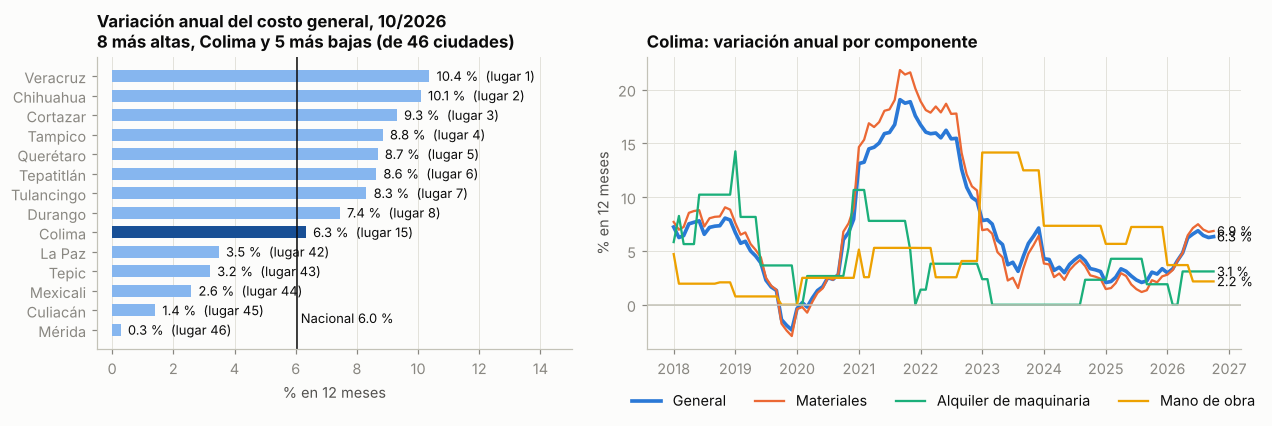

,ciudad,estado,region,var_anual_general,var_anual_mano_obra,var_anual_maquinaria,var_anual_materiales,lugar,var_anual_nacional,supera_nacional
14,Colima,Colima,Centro Norte,6.328,2.168,3.095,6.856,15,6.046,True
19,Jacona,Michoacán,Centro Norte,5.879,1.147,7.843,6.444,20,6.046,False
29,Morelia,Michoacán,Centro Norte,5.192,9.804,9.579,4.599,30,6.046,False
35,Guadalajara,Jalisco,Centro Norte,4.752,2.999,10.201,4.933,36,6.046,False


In [21]:
ult = pd.to_datetime(rk.fecha.iloc[0]); nacional = rk.var_anual_nacional.iloc[0]
d = pd.concat([rk.head(8), rk[rk.ciudad_id == "colima"], rk.tail(5)]).drop_duplicates("ciudad_id").sort_values("var_anual_general")
fig, axs = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axs[0]; ax.barh(d.ciudad, d.var_anual_general, color=["#184f95" if c == "colima" else "#86b6ef" for c in d.ciudad_id], height=0.62)
for y, (v, l) in enumerate(zip(d.var_anual_general, d.lugar)): ax.text(max(v, 0), y, f"  {v:.1f} %  (lugar {l})", va="center", fontsize=8.5)
ax.axvline(nacional, color="#0b0b0b", lw=1); ax.text(nacional, 0.6, f" Nacional {nacional:.1f} %", fontsize=8.5, va="center")
ax.set(title=f"Variación anual del costo general, {ult:%m/%Y}\n8 más altas, Colima y 5 más bajas (de 46 ciudades)", xlabel="% en 12 meses", xlim=(min(d.var_anual_general.min(), 0) - 0.5, d.var_anual_general.max() * 1.45)); ax.grid(axis="y", visible=False)
ax = axs[1]; c = panel[(panel.ciudad_id == "colima") & (panel.fecha >= "2018-01-01")]
for k in catalogos.COMPONENTES:
    s = c[c.componente == k]; ax.plot(s.fecha, s.var_anual_pct, color=COLOR[k], label=NOMBRE[k], lw=2.4 if k == "general" else 1.5)
    ax.text(s.fecha.iloc[-1] + pd.Timedelta(days=20), s.var_anual_pct.iloc[-1], f"{s.var_anual_pct.iloc[-1]:.1f} %", va="center", fontsize=8.5)
ax.axhline(0, color="#c3c2b7", lw=1); ax.set(title="Colima: variación anual por componente", ylabel="% en 12 meses"); ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()
display(rk[rk.ciudad_id.isin(["colima", "morelia", "jacona", "guadalajara"])].drop(columns=["ciudad_id", "fecha"]))

## 9. Limitaciones conocidas (se registran como pendientes para E2)

1. **La fuente puede volver a cambiar de estructura.** Ya pasó una vez (agosto de 2025) y el identificador de la estructura está fijo en `extractores/config.py`. Si INEGI vuelve a actualizar el índice, la serie dejará de avanzar; la revisión de oportunidad del dato lo detectaría, pero el identificador nuevo hay que localizarlo a mano.
2. **El tipo de cambio en bronce inicia en 2017**, por eso `fix_*` está vacío de 2004 a 2016 en oro. Se puede ampliar el histórico de Banxico sin cambiar el pipeline.
3. **El índice mide variación, no pesos.** Dice cuánto subió construir, no cuánto cuesta el bulto de cemento. Para convertirlo en presupuesto hace falta un precio base por ciudad (aportado por ferreterías o usuarios), que es justo lo que se validará en las entrevistas.
4. Los datos de CENACE de la propuesta original (E0) siguen en bronce y su captura diaria sigue activa, pero ya no forman parte del producto.